# HARTH Dataset — Exploratory Visualizations

Run cells in order after extracting the HARTH CSV files into `data/harth/`. Outputs are saved under `plots/harth/`. Participant ages are not included in the CSVs.

In [2]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


def find_data_dir():
    candidates = [
        Path("data/harth"),
        Path("harth"),
        Path("."),
    ]
    for candidate in candidates:
        if candidate.exists():
            csvs = sorted(candidate.rglob("*.csv"))
            if csvs:
                return candidate, csvs

    for root in [Path.cwd(), *Path.cwd().parents, Path.home()]:
        for match in sorted((root / "data").glob("**/harth"), key=lambda p: len(p.parts)) + sorted(root.glob("**/harth"), key=lambda p: len(p.parts)):
            if match.is_dir():
                csvs = sorted(match.rglob("*.csv"))
                if csvs:
                    return match, csvs

    return Path("data/harth"), []


DATA, detected_files = find_data_dir()
OUT = Path("plots/harth")
OUT.mkdir(parents=True, exist_ok=True)

files = detected_files or sorted(DATA.rglob("*.csv"))
if not files:
    raise FileNotFoundError(f"No CSV files found in {DATA.resolve()} or a nearby harth/ folder.")

LABELS = {
    1: "Walking", 2: "Running", 3: "Shuffling",
    4: "Stairs up", 5: "Stairs down", 6: "Standing",
    7: "Sitting", 8: "Lying", 13: "Cycling sitting",
    14: "Cycling standing", 130: "Cycling sitting",
    140: "Cycling standing"
}
# Preserve any additional labels as numeric IDs.

frames = []
for path in files:
    df = pd.read_csv(path)
    df.columns = df.columns.str.strip()
    if "label" not in df.columns:
        print(f"Skipping {path.name}: no label column")
        continue
    df["participant"] = path.stem
    frames.append(df)
if not frames:
    raise ValueError("No files with a 'label' column.")
data = pd.concat(frames, ignore_index=True)
data["activity"] = data["label"].map(LABELS).fillna(
    data["label"].astype(str)
)

print("Participants/files:", len(frames))
print("Rows:", len(data))
print("Columns:", list(data.columns))
print("Missing values:\n", data.isna().sum())
print("Label IDs:", sorted(data["label"].dropna().unique().tolist()))


Participants/files: 22
Rows: 6461328
Columns: ['timestamp', 'back_x', 'back_y', 'back_z', 'thigh_x', 'thigh_y', 'thigh_z', 'label', 'participant', 'index', 'Unnamed: 0', 'activity']
Missing values:
 timestamp            0
back_x               0
back_y               0
back_z               0
thigh_x              0
thigh_y              0
thigh_z              0
label                0
participant          0
index          5740689
Unnamed: 0     6323682
activity             0
dtype: int64
Label IDs: [1, 2, 3, 4, 5, 6, 7, 8, 13, 14, 130, 140]


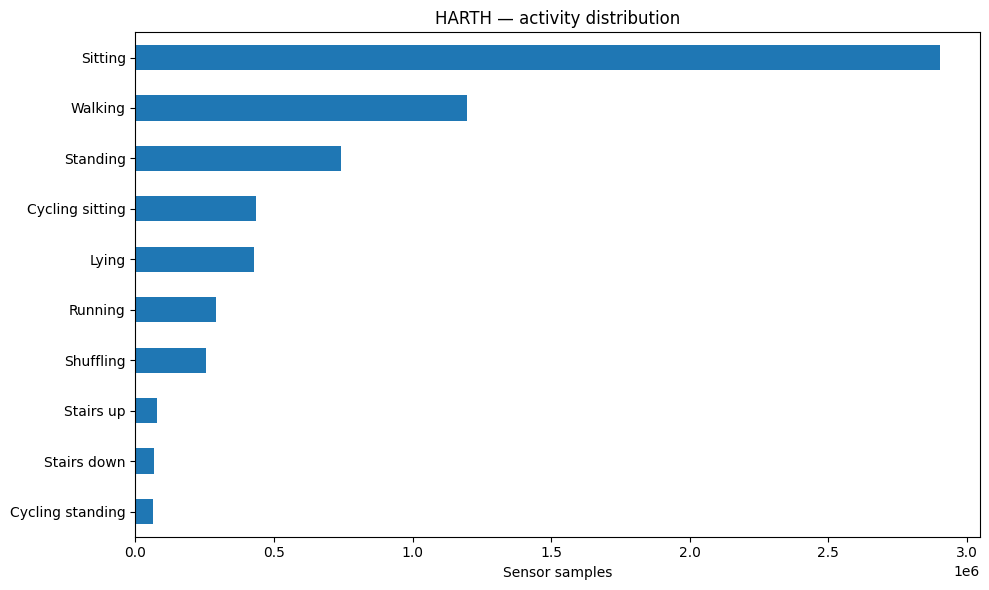

In [3]:
# 1. Overall activity distribution
counts = data["activity"].value_counts().sort_values()
ax = counts.plot.barh(figsize=(10, 6))
ax.set(title="HARTH — activity distribution", xlabel="Sensor samples", ylabel="")
plt.tight_layout()
plt.savefig(OUT / "01_activity_distribution.png", dpi=180)
plt.show()



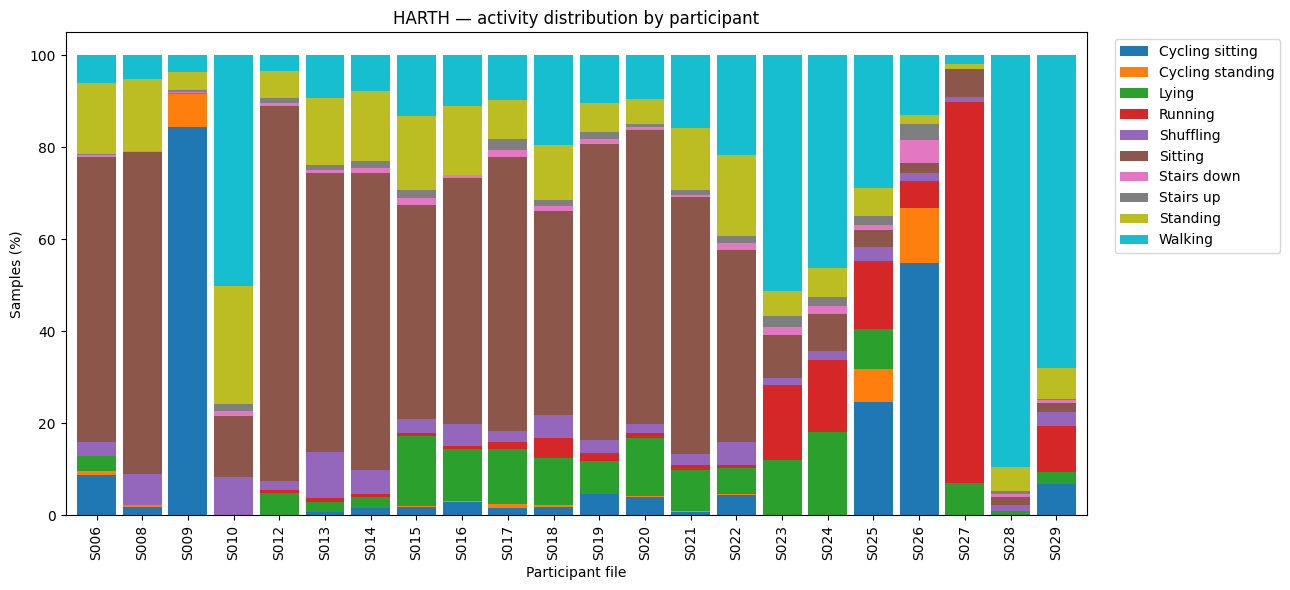

In [4]:
# 2. Activity proportions for each participant
pivot = pd.crosstab(data["participant"], data["activity"], normalize="index") * 100
ax = pivot.plot.bar(stacked=True, figsize=(13, 6), width=0.85)
ax.set(title="HARTH — activity distribution by participant", ylabel="Samples (%)", xlabel="Participant file")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.savefig(OUT / "02_participant_activities.png", dpi=180)
plt.show()



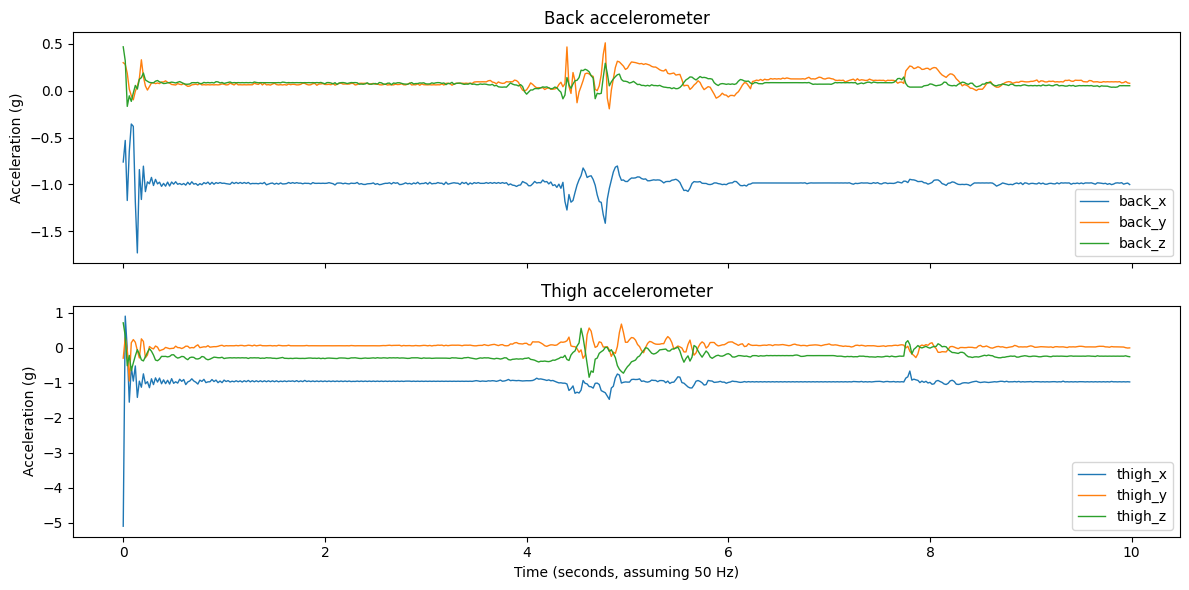

In [5]:
# 3. Raw sensor traces (first available recording)
first = frames[0]
sensor_cols = [c for c in first.columns if c.lower() in
               ["back_x", "back_y", "back_z", "thigh_x", "thigh_y", "thigh_z"]]
if sensor_cols:
    segment = first.iloc[:min(500, len(first))]
    fig, axes = plt.subplots(2, 1, figsize=(12, 6), sharex=True)
    for i, prefix in enumerate(["back_", "thigh_"]):
        cols = [c for c in sensor_cols if c.lower().startswith(prefix)]
        for c in cols:
            axes[i].plot(np.arange(len(segment)) / 50, segment[c], label=c, lw=1)
        axes[i].set(ylabel="Acceleration (g)", title=prefix[:-1].title() + " accelerometer")
        axes[i].legend()
    axes[-1].set_xlabel("Time (seconds, assuming 50 Hz)")
    plt.tight_layout()
    plt.savefig(OUT / "03_sensor_signals.png", dpi=180)
    plt.show()
else:
    print("Sensor columns not recognized; available columns:", list(first.columns))



In [6]:
# 4. Missing values by column
missing = data.isna().mean().mul(100).sort_values(ascending=False)
print("\nMissing percentage by column:\n", missing.round(3))
print("\nPlots saved to", OUT.resolve())



Missing percentage by column:
 Unnamed: 0     97.870
index          88.847
timestamp       0.000
back_x          0.000
back_y          0.000
back_z          0.000
thigh_x         0.000
thigh_y         0.000
thigh_z         0.000
label           0.000
participant     0.000
activity        0.000
dtype: float64

Plots saved to /Users/zeynepdogadellal/Documents/Masters/ML Case Study/ML-DL-Project/plots/harth


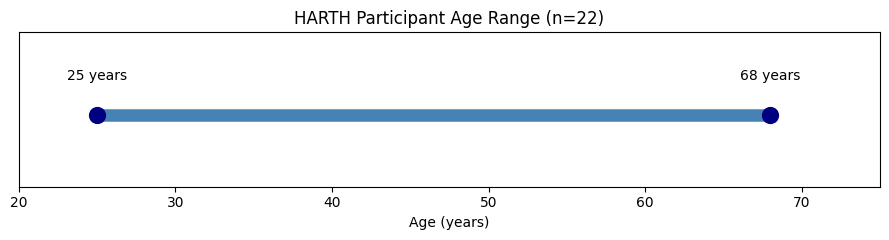

In [7]:
import matplotlib.pyplot as plt

# Published HARTH participant information
participants = 22
min_age = 25
max_age = 68

fig, ax = plt.subplots(figsize=(9, 2.5))

ax.plot([min_age, max_age], [0, 0],
        linewidth=9, color="steelblue", solid_capstyle="round")

ax.scatter([min_age, max_age], [0, 0],
           s=130, color="navy", zorder=3)

ax.text(min_age, 0.15, "25 years", ha="center")
ax.text(max_age, 0.15, "68 years", ha="center")

ax.set_xlim(20, 75)
ax.set_ylim(-0.3, 0.35)
ax.set_yticks([])
ax.set_xlabel("Age (years)")
ax.set_title(f"HARTH Participant Age Range (n={participants})")

plt.tight_layout()
plt.show()